# Stage 7: Machine learning classification and baseline evaluation

In [ ]:
## Stage 7: Machine learning classification and baseline evaluation (Person 6)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, warnings
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score, accuracy_score, roc_auc_score)
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
os.makedirs("outputs", exist_ok=True)

In [ ]:
import os, shutil
from google.colab import files
os.makedirs("data/person2", exist_ok=True)
print("Select ONLY metadata.csv:")
up = files.upload()
for fn in up.keys():
    shutil.move(fn, "data/person2/clean_metadata.csv")
print(os.listdir("data/person2"))

Select ONLY metadata.csv:


Saving metadata.csv to metadata.csv
['clean_metadata.csv', 'clean_expression.csv']


In [ ]:
import shutil
os.makedirs("data/person2", exist_ok=True)
CLEAN_EXPR = "data/person2/clean_expression.csv"
CLEAN_META = "data/person2/clean_metadata.csv"

# If the files are not here yet, ask for them (select BOTH in one go)
if not (os.path.exists(CLEAN_EXPR) and os.path.exists(CLEAN_META)):
    from google.colab import files
    print("Click 'Choose Files' and select BOTH clean_expression.csv and clean_metadata.csv:")
    up = files.upload()
    for fn in up.keys():
        low = fn.lower()
        if "metadata" in low:
            shutil.move(fn, CLEAN_META)
        elif "expression" in low:
            shutil.move(fn, CLEAN_EXPR)

expr = pd.read_csv(CLEAN_EXPR, index_col=0)   # genes x samples (Person 2's file)
meta = pd.read_csv(CLEAN_META, index_col=0).rename_axis("sample_id").reset_index()   # first column = sample ID

# make rows = samples, columns = genes
if meta["sample_id"].isin(expr.columns).mean() > 0.5:
    expr = expr.T
expr.index = expr.index.astype(str)
meta["sample_id"] = meta["sample_id"].astype(str)

# align by sample_id (never rely on row order)
meta = meta.set_index("sample_id").loc[expr.index.intersection(meta["sample_id"])]
expr = expr.loc[meta.index]
X = expr.apply(pd.to_numeric, errors="coerce")

# safety check: Person 2 already made gene symbols unique and applied log2(x+1)
assert X.columns.is_unique, "Duplicate gene symbols found - this does not look like the cleaned file"
if X.max().max() > 100:
    raise ValueError("Values look un-logged; check you uploaded clean_expression.csv, not the raw matrix.")

y = meta["label"].astype(int).values
groups = meta["patient_id"].values
print("X (samples x genes):", X.shape, "| missing values:", int(X.isna().sum().sum()))
print("Patients:", len(set(groups)), "| samples per patient:", pd.Series(groups).value_counts().unique())

X (samples x genes): (86, 13237) | missing values: 0
Patients: 43 | samples per patient: [2]


In [ ]:
bal = pd.Series(y).map({0:"Normal",1:"Tumour"}).value_counts().rename("n_samples").to_frame()
bal["fraction"] = (bal["n_samples"]/bal["n_samples"].sum()).round(3)
display(bal)

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
tr, te = next(gss.split(X, y, groups))
X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y[tr], y[te]
assert set(groups[tr]).isdisjoint(set(groups[te])), "patient leakage!"
print(f"Train: {len(tr)} samples ({len(set(groups[tr]))} patients) | Test: {len(te)} samples ({len(set(groups[te]))} patients)")
print("Test class counts:", {int(k): int(v) for k, v in zip(*np.unique(y_te, return_counts=True))})

,n_samples,fraction
Normal,43,0.5
Tumour,43,0.5


Train: 64 samples (32 patients) | Test: 22 samples (11 patients)
Test class counts: {0: 11, 1: 11}


In [ ]:
K = 200  # genes kept by univariate F-test; fixed in advance
def prep():
    return [("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("select", SelectKBest(f_classif, k=min(K, X.shape[1])))]

models = {
    "Dummy baseline": Pipeline([("clf", DummyClassifier(strategy="stratified", random_state=SEED))]),
    "Logistic regression (primary)": Pipeline(prep() + [("clf", LogisticRegression(C=0.1, max_iter=5000, random_state=SEED))]),
    "SVM (linear)": Pipeline(prep() + [("clf", SVC(kernel="linear", C=0.1, probability=True, random_state=SEED))]),
    "Random forest": Pipeline(prep() + [("clf", RandomForestClassifier(n_estimators=300, random_state=SEED))]),
}
for m in models.values():
    m.fit(X_tr, y_tr)

,model,accuracy,precision,recall,f1,roc_auc
0,Dummy baseline,0.409,0.417,0.455,0.435,0.409
1,Logistic regression (primary),0.818,0.818,0.818,0.818,0.901
2,SVM (linear),0.818,0.818,0.818,0.818,0.884
3,Random forest,0.818,0.818,0.818,0.818,0.868


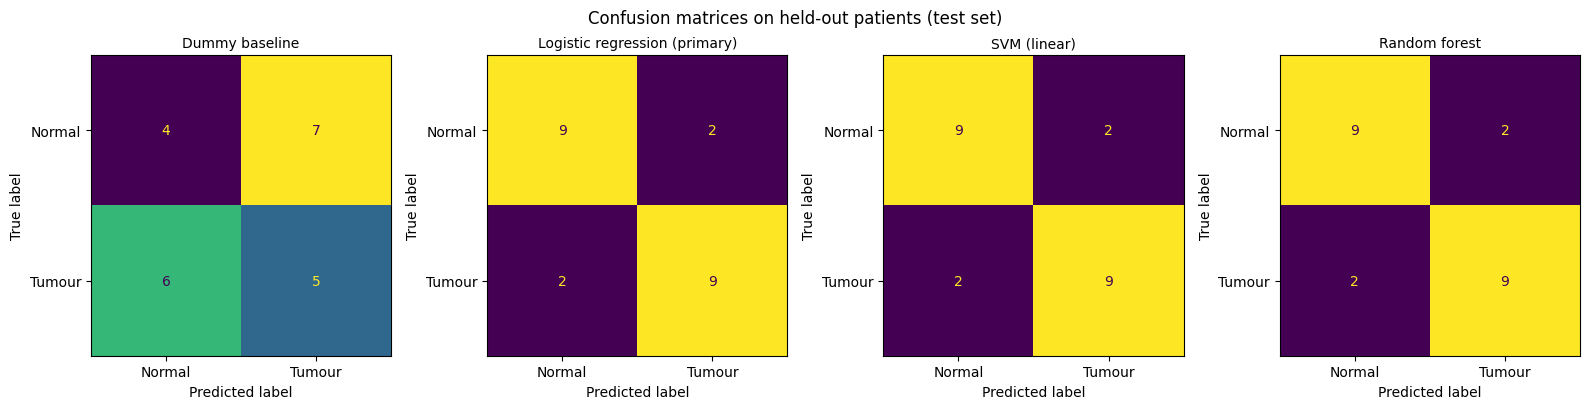

In [ ]:
rows, preds = [], {}
for name, est in models.items():
    pred = est.predict(X_te); preds[name] = pred
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_te, pred),
                 "precision": precision_score(y_te, pred, zero_division=0),
                 "recall": recall_score(y_te, pred, zero_division=0),
                 "f1": f1_score(y_te, pred, zero_division=0),
                 "roc_auc": roc_auc_score(y_te, est.predict_proba(X_te)[:, 1])})
metrics = pd.DataFrame(rows).round(3)
metrics.to_csv("outputs/model_metrics.csv", index=False)
display(metrics)

fig, axes = plt.subplots(1, len(models), figsize=(4*len(models), 4))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=[0,1]),
                           display_labels=["Normal","Tumour"]).plot(ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
fig.suptitle("Confusion matrices on held-out patients (test set)")
plt.tight_layout(); plt.savefig("outputs/confusion_matrix.png", dpi=200); plt.show()

,model,accuracy,f1,roc_auc
0,Dummy baseline,0.350 ± 0.020,0.350 ± 0.020,0.350 ± 0.020
1,Logistic regression (primary),0.872 ± 0.041,0.871 ± 0.039,0.976 ± 0.017
2,SVM (linear),0.863 ± 0.054,0.860 ± 0.050,0.951 ± 0.030
3,Random forest,0.874 ± 0.039,0.871 ± 0.041,0.977 ± 0.024


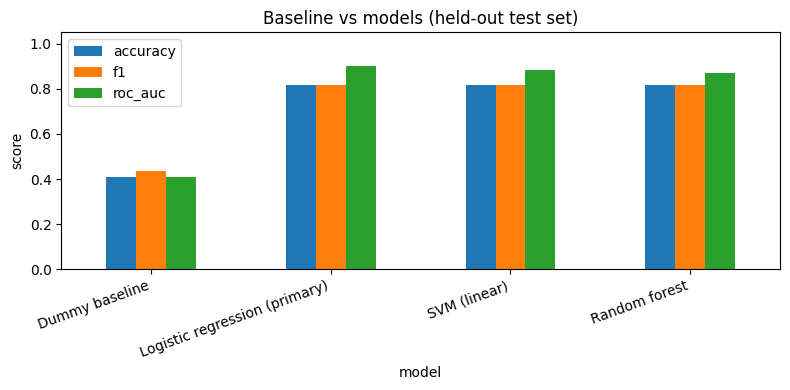

In [ ]:
cv = GroupKFold(n_splits=5)
scoring = {"accuracy":"accuracy","f1":"f1","roc_auc":"roc_auc"}
rows = []
for name, est in models.items():
    res = cross_validate(est, X, y, groups=groups, cv=cv, scoring=scoring)
    row = {"model": name}
    for m in scoring:
        v = res[f"test_{m}"]; row[m] = f"{v.mean():.3f} ± {v.std():.3f}"
    rows.append(row)
cv_table = pd.DataFrame(rows)
cv_table.to_csv("outputs/model_metrics_cv.csv", index=False)
display(cv_table)

fig, ax = plt.subplots(figsize=(8,4))
metrics.set_index("model")[["accuracy","f1","roc_auc"]].plot(kind="bar", ax=ax)
ax.set_ylim(0,1.05); ax.set_ylabel("score"); ax.set_title("Baseline vs models (held-out test set)")
plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig("outputs/baseline_vs_model.png", dpi=200); plt.show()

In [ ]:
import shutil
shutil.make_archive("stage7_outputs", "zip", "outputs")
try:
    from google.colab import files
    files.download("stage7_outputs.zip")
except Exception as e:
    print("Not in Colab, outputs are in the 'outputs' folder:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Leakage-prevention note
- The split is by `patient_id`, so a patient's tumour and matched normal sample are never separated across train and test.
- Imputation, scaling and gene selection (top-200 by F-test) are Pipeline steps fitted on training folds only.
- Person 2's only transformations, log2(x+1) and merging duplicate gene symbols, are fixed or label-free steps, so they cannot carry information from test samples into training.
- The test set was used once for the final evaluation; k, C and the forest size were fixed in advance, not tuned on it. Logistic regression is the pre-declared primary model; SVM and random forest are comparisons, not a search for the best test score.
- Gene lists from Person 4 were deliberately not used for feature selection, because they were chosen using all samples.


### Interpretation

**Result vs baseline.** All three models clearly beat the baseline. On the held-out test split (11 patients, 22 samples), the dummy baseline reached 40.9% accuracy (F1 0.435, ROC-AUC 0.409), which is chance level. Logistic regression, SVM and random forest each reached 81.8% accuracy and F1 0.818, with ROC-AUC of 0.901, 0.884 and 0.868 respectively. Each model made 4 errors out of 22: 2 normal samples predicted as tumour and 2 tumour samples predicted as normal. In patient-grouped 5-fold cross-validation (mean ± SD), the baseline scored 0.350 ± 0.020 accuracy, while logistic regression scored 0.872 ± 0.041 (F1 0.871, ROC-AUC 0.976), SVM 0.863 ± 0.054 and random forest 0.874 ± 0.039. So expression profiles did improve prediction over the baseline by a large margin.

**No clear winner among the models.** The three models differ by about one percentage point in cross-validation accuracy, far less than the fold-to-fold spread of 4–5 points. This data gives no evidence that one model is better than another. Logistic regression was declared the primary model beforehand and is reported as such.

**Uncertainty.** The test split contains only 22 samples, so each misclassified sample moves accuracy by about 4.5 percentage points. The test accuracy (0.818) sits below the cross-validated accuracy (about 0.87), which is consistent with this noise rather than a sign of overfitting. The cross-validation figures, which use all 43 patients, are the more reliable summary. The ± values reflect only 5 folds and are themselves rough. The dummy baseline is a random guesser, so its exact score (below 50% here) reflects chance in a small sample; the useful point is that it is far below the models.

**What this does and does not show.** The results show that gene expression separates breast tumour from adjacent normal tissue in this cohort better than guessing. They do not show that the model would work clinically or in other cohorts, and they do not show that the genes the models rely on cause the disease. Accuracy of 82–87% is lower than one might expect for tumour vs normal, so it is possible that low-quality samples or the small sample size play a role; this was not tested.

**Caveats.**
- 86 samples from 43 patients, one cohort, no external validation.
- Processed microarray intensities (not RNA-seq counts).
- Person 2 flagged five low-correlation samples from four patients; they were kept, so these results include them.
- Gene selection and all models were fixed in advance and not tuned on the test set.